# 01 — Volatility Dynamics baseline from first principles

## Independence contract

This notebook is intentionally independent of every other research branch.

It **does not import or consume**:

- HSMM outputs, code, state definitions, HAR models, or frozen specifications;
- Volatility Regression outputs, models, selected features, or confirmation logic;
- Volatility Risk Premium outputs or option-pricing conventions;
- Pairwise Feature Regression outputs, correlations, clock findings, or feature selections.

The only project input is the shared research database relation `time_series_feature_state`, and Module 01 reads only three base columns:

`state_time`, `underlying`, `return_5m`.

All volatility objects, thresholds, clock diagnostics, persistence statistics and episode definitions are constructed inside this branch from those columns.

## Research question

Before forecasting volatility or imposing latent states, what does the volatility process itself look like?

Module 01 establishes:

1. realized-variance distributions at several backward horizons;
2. whether a deterministic UTC clock pattern exists **in this branch's own data**;
3. persistence of volatility and association between current and subsequent realized variance;
4. duration and shape of high-volatility episodes;
5. buildup and decay around the onset of those episodes.

No MOM, MR, VS, Bridge, HMM, HSMM, or predictive-state label is used here.


In [1]:
from pathlib import Path
import json, os, sys, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 260)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_dynamics as vd

START = os.getenv('VD_START', '').strip() or None
END = os.getenv('VD_END', '').strip() or None
ASSET_FILTER = [x.strip().upper() for x in os.getenv('VD_ASSETS', '').split(',') if x.strip()]
HIGH_VOL_Q = float(os.getenv('VD_HIGH_VOL_Q', '0.90'))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '01'
OUT.mkdir(parents=True, exist_ok=True)

print('volatility_dynamics', vd.VOLATILITY_DYNAMICS_VERSION)
print('selftest:', vd.selftest())
print('window:', START or 'earliest available', '->', END or 'latest available')
print('high-vol threshold quantile:', HIGH_VOL_Q)


volatility_dynamics 0.2.1
selftest: {'bar_inference': True, 'timestamp_unit_normalization': True, 'backward_rv': True, 'forward_rv': True, 'gap_guard': True, 'episodes': True}
window: earliest available -> latest available
high-vol threshold quantile: 0.9


## 1. Load only timestamp, asset and raw 5-minute index return

No research-branch feature is read. Optional start/end filters exist only for reproducibility; the default is the entire available database history.


In [2]:
con = duckdb.connect(str(DB_PATH), read_only=True)
available = set(con.execute('DESCRIBE time_series_feature_state').df()['column_name'])
required = {'state_time','underlying','return_5m'}
missing = sorted(required - available)
if missing:
    raise RuntimeError(f'time_series_feature_state lacks required columns: {missing}')

where = []
if START:
    where.append(f"state_time >= TIMESTAMPTZ '{pd.Timestamp(START, tz='UTC').isoformat()}'")
if END:
    where.append(f"state_time <= TIMESTAMPTZ '{(pd.Timestamp(END, tz='UTC') + pd.Timedelta(days=1)).isoformat()}'")
if ASSET_FILTER:
    where.append('underlying IN (' + ','.join(repr(x) for x in ASSET_FILTER) + ')')
where_sql = '' if not where else ' WHERE ' + ' AND '.join(where)
df = con.execute(
    'SELECT state_time, underlying, return_5m FROM time_series_feature_state'
    + where_sql + ' ORDER BY underlying, state_time'
).df()
con.close()
df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
if df.empty:
    raise RuntimeError('No rows found for requested data window.')
dupes = int(df.duplicated(['underlying','state_time']).sum())
if dupes:
    raise RuntimeError(f'Found {dupes} duplicate asset/timestamp rows; resolve data integrity before research.')
print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())}')
print(df.state_time.min(), '->', df.state_time.max())


rows 38,304 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
2026-09-19 08:00:00+00:00 -> 2026-10-08 07:55:00+00:00


## 2. Construct volatility objects independently

For a backward window of (k) contiguous five-minute returns,

\[
RV^{back}_{t,k}=\sum_{j=0}^{k-1} r_{t-j}^2,
\qquad
Rate^{back}_{t,k}=RV^{back}_{t,k}/k.
\]

For descriptive current-versus-future association only,

\[
RV^{fwd}_{t,k}=\sum_{j=1}^{k} r_{t+j}^2.
\]

Every window requires a complete exact timestamp grid; windows crossing gaps are missing rather than rescaled.


In [3]:
panels, metas, eps_tables = [], [], []
for asset, g in df.groupby('underlying', sort=True):
    p, meta, eps = vd.build_volatility_panel(g)
    panels.append(p)
    metas.append(meta.__dict__)
    eps_tables.append(eps)
    print(asset, '| bar minutes', meta.bar_minutes, '| rows', meta.n_rows, '| finite return share', round(meta.finite_return_share,4))
panel = pd.concat(panels, ignore_index=True)
panel_meta = pd.DataFrame(metas)
epsilons = pd.concat(eps_tables, ignore_index=True)
coverage = vd.data_coverage(panel)
dist = vd.rv_distribution(panel)
display(panel_meta)
display(coverage)


AVAX | bar minutes 5.0 | rows 5472 | finite return share 0.8618
BTC | bar minutes 5.0 | rows 5472 | finite return share 0.8618
ETH | bar minutes 5.0 | rows 5472 | finite return share 0.8618
HYPE | bar minutes 5.0 | rows 5472 | finite return share 0.8618
SOL | bar minutes 5.0 | rows 5472 | finite return share 0.8618
TRX | bar minutes 5.0 | rows 5472 | finite return share 0.8615
XRP | bar minutes 5.0 | rows 5472 | finite return share 0.8618


,underlying,bar_minutes,n_rows,first_time,last_time,finite_return_share
0,AVAX,5.0,5472,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,0.861842
1,BTC,5.0,5472,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,0.861842
2,ETH,5.0,5472,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,0.861842
3,HYPE,5.0,5472,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,0.861842
4,SOL,5.0,5472,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,0.861842
5,TRX,5.0,5472,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,0.861477
6,XRP,5.0,5472,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,0.861842


,underlying,series,n_rows,n_finite,coverage
0,AVAX,return_5m,5472,4716,0.861842
1,AVAX,back_rate_5m,5472,4716,0.861842
2,AVAX,back_rate_15m,5472,4580,0.836988
3,AVAX,back_rate_30m,5472,4397,0.803545
4,AVAX,back_rate_60m,5472,4077,0.745066
5,AVAX,back_rate_4h,5472,2722,0.497442
6,AVAX,fwd_rate_30m,5472,4397,0.803545
7,AVAX,fwd_rate_60m,5472,4077,0.745066
8,BTC,return_5m,5472,4716,0.861842
9,BTC,back_rate_5m,5472,4716,0.861842


## 3. Distribution of realized volatility

This is the first empirical object in the branch. We inspect scale, skew and tail concentration before any state or forecasting assumption.


,underlying,series,n,mean,std,q01,q10,q25,median,q75,q90,q99,max
0,AVAX,back_rate_5m,4716,8.645200e-06,2.440150e-05,0.000000e+00,7.360000e-08,4.109000e-07,2.079900e-06,7.732400e-06,2.099300e-05,9.890330e-05,5.303477e-04
1,AVAX,back_rate_15m,4580,8.610900e-06,1.556230e-05,9.970000e-08,5.921000e-07,1.608900e-06,4.119500e-06,9.529700e-06,1.922710e-05,7.452460e-05,2.077131e-04
2,AVAX,back_rate_30m,4397,8.610000e-06,1.215190e-05,2.871000e-07,1.072200e-06,2.373500e-06,5.127600e-06,9.971500e-06,1.818230e-05,6.367120e-05,1.286507e-04
3,AVAX,back_rate_60m,4077,8.613600e-06,9.436700e-06,3.877000e-07,1.438200e-06,3.082500e-06,5.772200e-06,1.046800e-05,1.830360e-05,5.427510e-05,6.876630e-05
4,AVAX,back_rate_4h,2722,8.511900e-06,6.217300e-06,6.229000e-07,2.069800e-06,4.112100e-06,6.655200e-06,1.200500e-05,1.769310e-05,2.432010e-05,3.391110e-05
5,AVAX,fwd_rate_30m,4397,8.610000e-06,1.215190e-05,2.871000e-07,1.072200e-06,2.373500e-06,5.127600e-06,9.971500e-06,1.818230e-05,6.367120e-05,1.286507e-04
6,AVAX,fwd_rate_60m,4077,8.613600e-06,9.436700e-06,3.877000e-07,1.438200e-06,3.082500e-06,5.772200e-06,1.046800e-05,1.830360e-05,5.427510e-05,6.876630e-05
7,BTC,back_rate_5m,4716,1.118700e-06,3.758600e-06,0.000000e+00,5.800000e-09,4.170000e-08,2.221000e-07,8.471000e-07,2.424100e-06,1.369510e-05,1.255495e-04
8,BTC,back_rate_15m,4580,1.096600e-06,2.468600e-06,7.000000e-09,5.530000e-08,1.656000e-07,4.213000e-07,1.065200e-06,2.464500e-06,1.078790e-05,4.492710e-05
9,BTC,back_rate_30m,4397,1.084400e-06,1.934700e-06,1.730000e-08,1.014000e-07,2.247000e-07,5.148000e-07,1.167700e-06,2.358000e-06,9.429900e-06,2.297080e-05


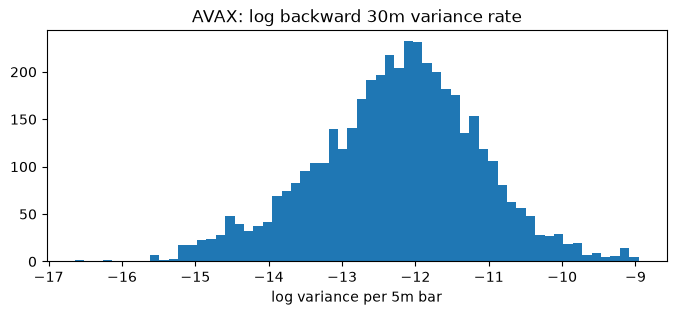

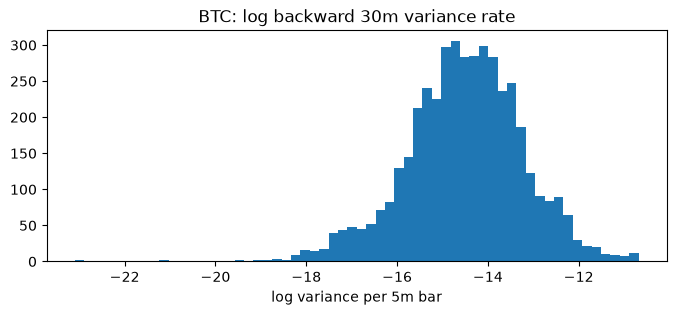

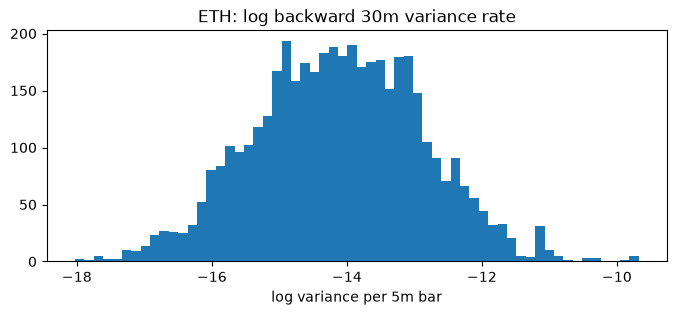

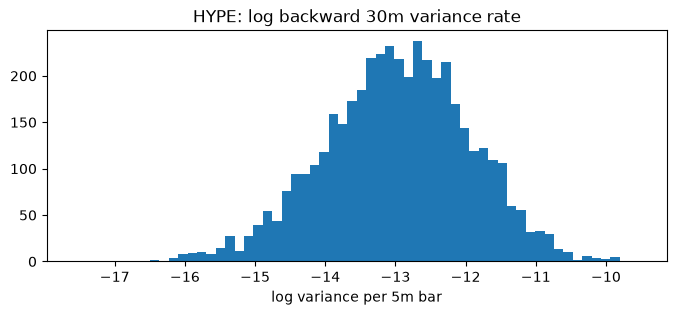

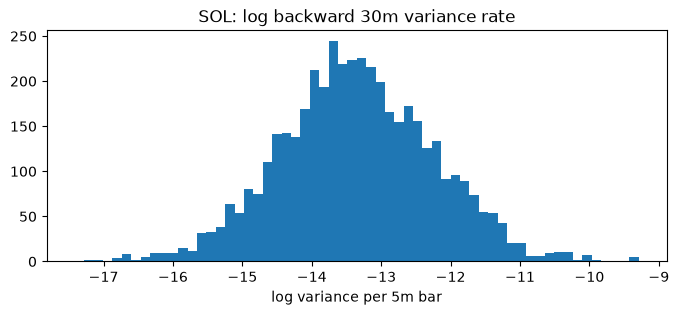

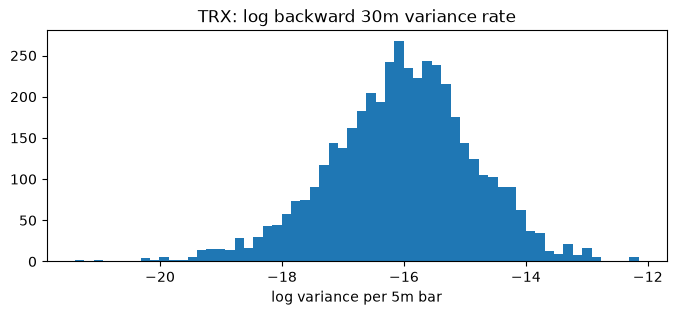

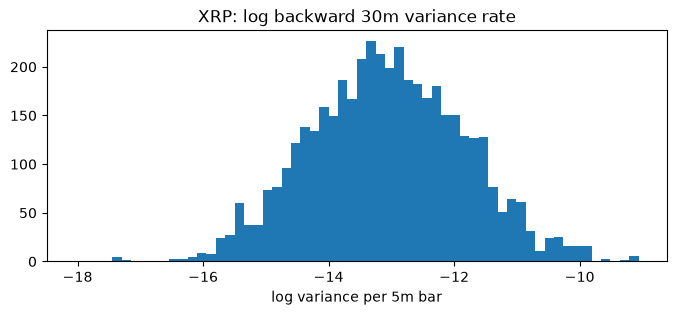

In [4]:
display(dist.round(10))

for asset in sorted(panel.underlying.unique()):
    x = panel.loc[panel.underlying == asset, 'log_back_rate_30m'].dropna()
    if len(x):
        fig, ax = plt.subplots(figsize=(8,3))
        ax.hist(x, bins=60)
        ax.set_title(f'{asset}: log backward 30m variance rate')
        ax.set_xlabel('log variance per 5m bar')
        plt.show()


## 4. Does this branch independently find UTC clock structure?

We do not assume the answer. For each exact five-minute UTC slot, we compute the median log backward 30m variance rate across dates, then compare the cross-clock amplitude with the pooled interquartile range.


,underlying,n_clock_slots,slot_median_q10,slot_median_q90,clock_amplitude_q90_q10,pooled_iqr,clock_amplitude_to_pooled_iqr
0,AVAX,288,-12.6753,-11.6845,0.9908,1.4352,0.6904
1,BTC,288,-14.9939,-13.5739,1.4200,1.6478,0.8617
2,ETH,288,-14.6654,-13.1763,1.4891,1.7469,0.8524
3,HYPE,288,-13.3837,-12.3262,1.0575,1.3887,0.7615
4,SOL,288,-13.7998,-12.7184,1.0814,1.4686,0.7364
5,TRX,288,-16.6261,-15.4782,1.1479,1.5072,0.7616
6,XRP,288,-13.5787,-12.3497,1.2290,1.6977,0.7239


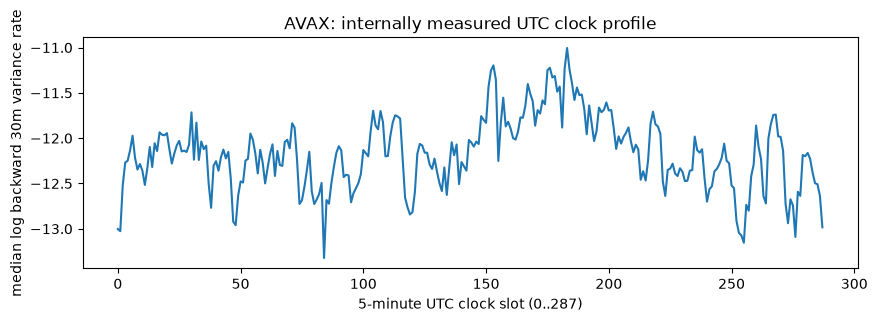

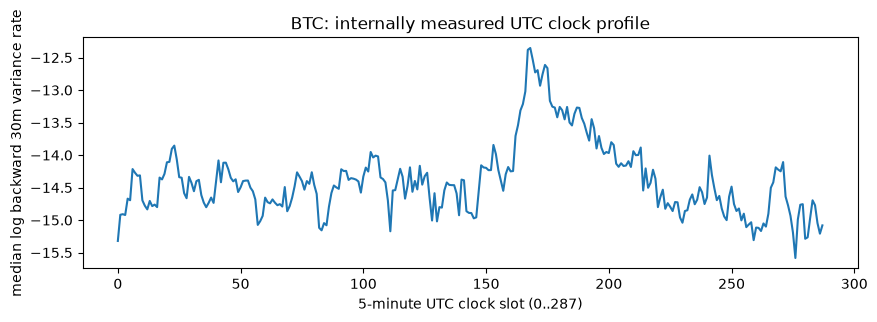

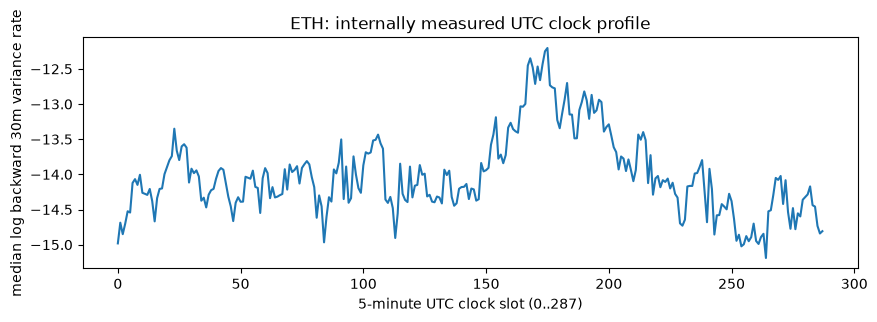

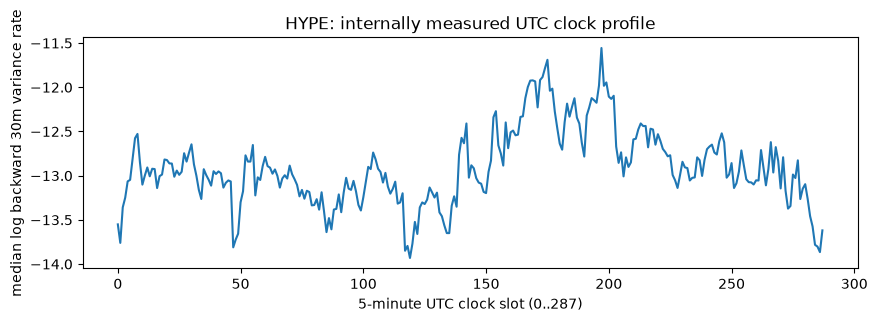

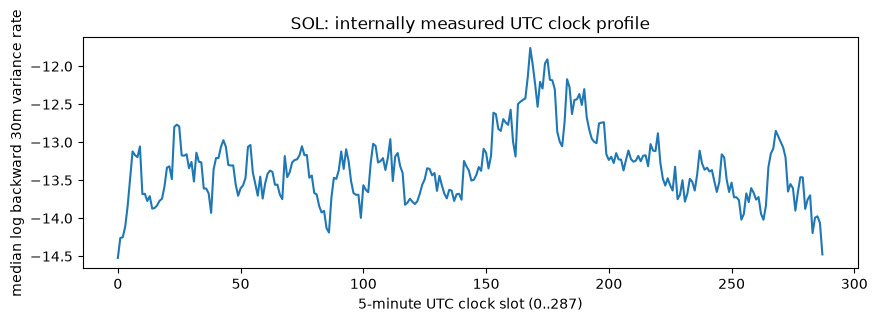

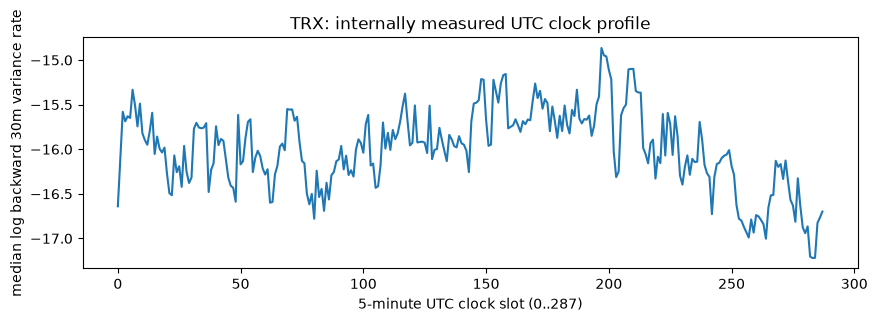

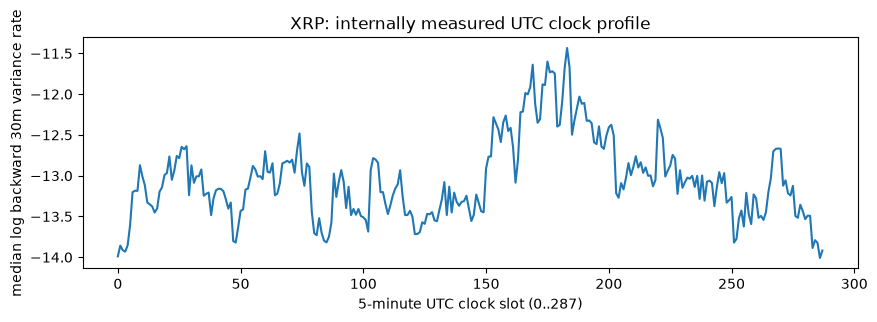

In [5]:
clock_profile, clock_summary = vd.clock_profile(panel)
display(clock_summary.round(4))

for asset in sorted(panel.underlying.unique()):
    g = clock_profile[clock_profile.underlying == asset].sort_values('clock_slot')
    if len(g):
        fig, ax = plt.subplots(figsize=(10,3))
        ax.plot(g.clock_slot, g['median'])
        ax.set_title(f'{asset}: internally measured UTC clock profile')
        ax.set_xlabel('5-minute UTC clock slot (0..287)')
        ax.set_ylabel('median log backward 30m variance rate')
        plt.show()


## 5. Volatility persistence from raw returns

We report overlapping autocorrelations and current-backward-vs-future associations, plus non-overlapping 30m/60m origin subsets. These are descriptive dependence statistics, not a predictive model.


In [6]:
persistence = vd.persistence_summary(panel)
display(persistence.pivot(index='underlying', columns='relationship', values='corr').round(3))


relationship,back30_autocorr_15m,back30_autocorr_30m,back30_autocorr_4h,back30_autocorr_5m,back30_autocorr_60m,back30_vs_fwd30m_all,back30_vs_fwd30m_nonoverlap,back30_vs_fwd60m_all,back30_vs_fwd60m_nonoverlap
underlying,,,,,,,,,
AVAX,0.738,0.490,0.352,0.914,0.434,0.490,0.466,0.522,0.527
BTC,0.802,0.609,0.364,0.936,0.542,0.609,0.593,0.632,0.589
ETH,0.795,0.587,0.380,0.934,0.518,0.587,0.574,0.598,0.573
HYPE,0.736,0.484,0.304,0.914,0.413,0.484,0.476,0.517,0.492
SOL,0.723,0.460,0.316,0.909,0.395,0.460,0.449,0.493,0.512
TRX,0.639,0.343,0.183,0.877,0.280,0.343,0.315,0.364,0.339
XRP,0.803,0.612,0.463,0.935,0.556,0.612,0.593,0.642,0.625


## 6. High-volatility episodes, defined without a forecast model

For each asset, an episode is a contiguous run where the backward 30m variance rate is at or above that asset's full-sample 90th percentile (configurable with `VD_HIGH_VOL_Q`).

This is a retrospective descriptive threshold chosen inside this branch. It is **not** a live state definition and it is not adjusted for clock in Module 01. The clock analysis above tells us whether a later module needs that adjustment.


In [7]:
thresholds = vd.high_vol_thresholds(panel, q=HIGH_VOL_Q)
episodes = vd.extract_high_vol_episodes(panel, thresholds)
episode_summary = vd.episode_summary(episodes)
display(thresholds)
display(episode_summary.round(4))


,underlying,series,quantile,n,threshold
0,AVAX,back_rate_30m,0.9,4397,1.818226e-05
1,BTC,back_rate_30m,0.9,4397,2.357972e-06
2,ETH,back_rate_30m,0.9,4397,3.685063e-06
3,HYPE,back_rate_30m,0.9,4397,8.908244e-06
4,SOL,back_rate_30m,0.9,4397,6.726816e-06
5,TRX,back_rate_30m,0.9,4390,4.943787e-07
6,XRP,back_rate_30m,0.9,4397,1.010009e-05


,underlying,n_episodes,n_right_censored,median_duration_min,q75_duration_min,q90_duration_min,median_peak_value,median_anchor_slope_15v60,median_anchor_slope_30v4h,median_anchor_delta_back30_15m,median_anchor_delta_back30_30m,median_anchor_delta_back30_60m
0,AVAX,82,0,25.0,35.0,50.0,0.0,0.8071,0.7235,0.9356,1.2335,1.2567
1,BTC,74,0,30.0,35.0,50.0,0.0,0.8427,0.8842,0.9888,1.3291,1.1001
2,ETH,80,0,30.0,30.0,45.5,0.0,0.7648,0.9526,0.7884,1.2797,1.2894
3,HYPE,90,0,20.0,30.0,40.0,0.0,0.7475,0.5817,0.8324,1.0732,1.0818
4,SOL,84,0,30.0,30.0,43.5,0.0,0.7539,0.6571,0.9537,1.1672,1.1067
5,TRX,92,0,30.0,30.0,35.0,0.0,0.8103,1.0255,0.9811,1.4111,1.4537
6,XRP,84,0,25.0,35.0,45.0,0.0,0.6882,0.6817,0.7419,0.9597,1.2019


## 7. Buildup and decay around episode onset

The anchor is the first bar crossing into the high-volatility region. Paths use volatility measures derived only from returns. No flow, IV, order-book, or cross-branch feature is examined yet.


path summary rows: 4270


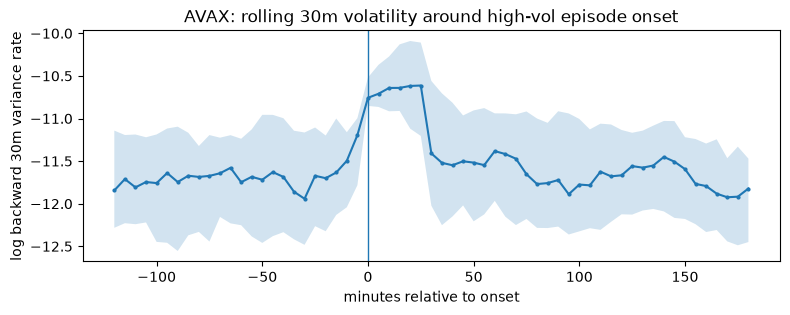

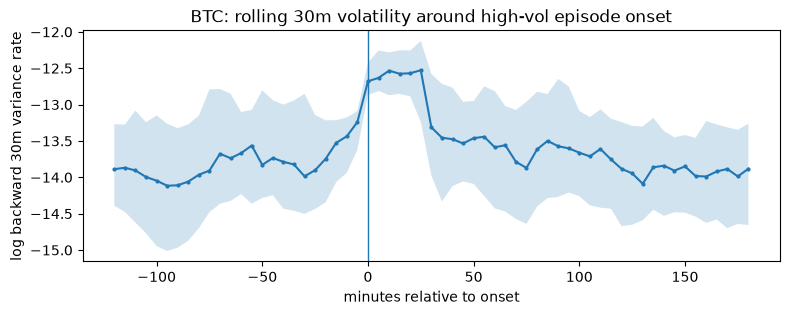

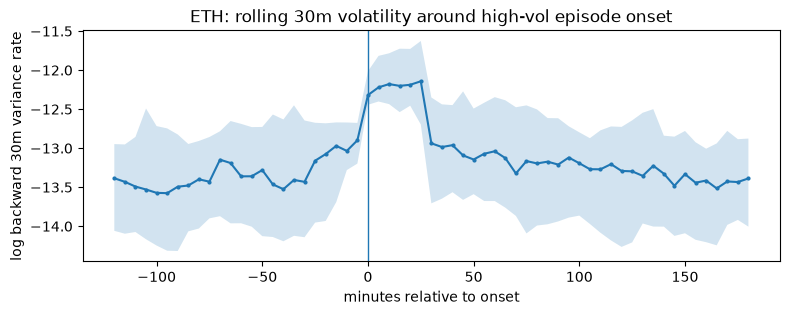

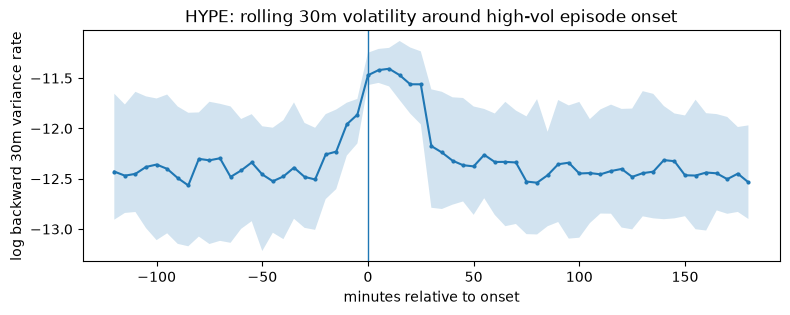

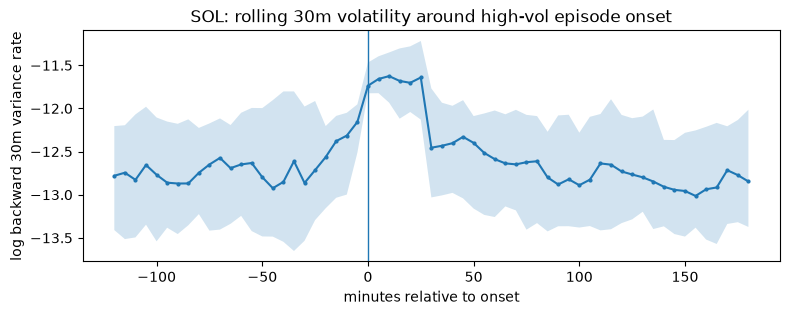

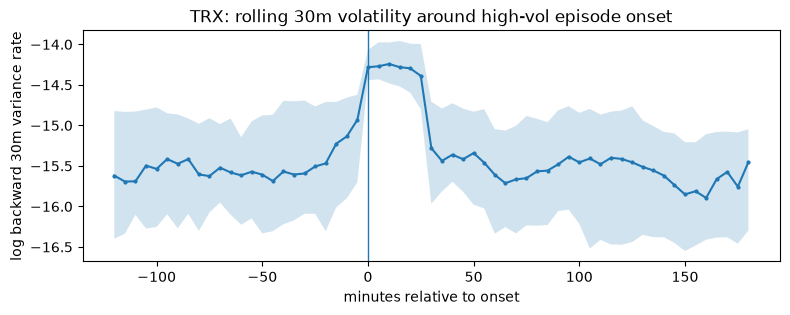

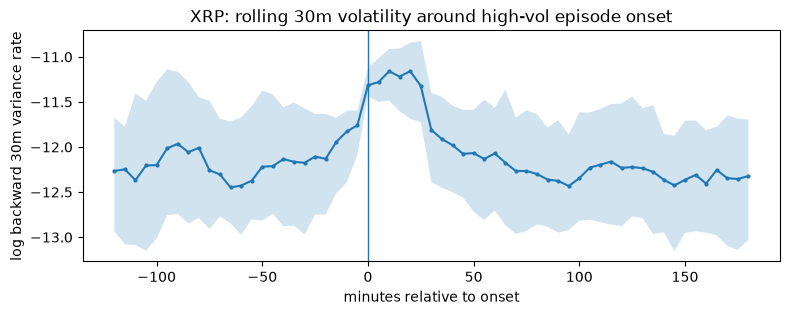

In [8]:
paths = vd.event_path_summary(panel, episodes, pre_min=120, post_min=180)
print('path summary rows:', len(paths))

for asset in sorted(panel.underlying.unique()):
    g = paths[(paths.underlying == asset) & (paths.variable == 'log_back_rate_30m')].sort_values('rel_min')
    if len(g):
        fig, ax = plt.subplots(figsize=(9,3))
        ax.plot(g.rel_min, g['median'], marker='o', markersize=2)
        ax.fill_between(g.rel_min, g.q25, g.q75, alpha=0.2)
        ax.axvline(0, linewidth=1)
        ax.set_title(f'{asset}: rolling 30m volatility around high-vol episode onset')
        ax.set_xlabel('minutes relative to onset')
        ax.set_ylabel('log backward 30m variance rate')
        plt.show()


## 8. Persist compact, branch-local outputs

No full state panel is committed. Everything below can be rebuilt from the base database and this standalone engine.


In [9]:
panel_meta.to_csv(OUT / '01_panel_metadata.csv', index=False)
epsilons.to_csv(OUT / '01_log_epsilons.csv', index=False)
coverage.to_csv(OUT / '01_data_coverage.csv', index=False)
dist.to_csv(OUT / '01_rv_distribution.csv', index=False)
clock_profile.to_csv(OUT / '01_clock_profile.csv', index=False)
clock_summary.to_csv(OUT / '01_clock_effect_summary.csv', index=False)
persistence.to_csv(OUT / '01_persistence.csv', index=False)
thresholds.to_csv(OUT / '01_high_vol_thresholds.csv', index=False)
episodes.to_csv(OUT / '01_high_vol_episodes.csv', index=False)
episode_summary.to_csv(OUT / '01_high_vol_episode_summary.csv', index=False)
paths.to_csv(OUT / '01_high_vol_paths.csv', index=False)

meta = {
    'version': vd.VOLATILITY_DYNAMICS_VERSION,
    'independence_contract': 'No imports or outputs from any other research branch; only state_time, underlying, return_5m from time_series_feature_state.',
    'database_relation': 'time_series_feature_state',
    'database_columns_read': ['state_time','underlying','return_5m'],
    'database_read_only': True,
    'start': START or 'earliest_available',
    'end': END or 'latest_available',
    'assets': sorted(panel.underlying.unique().tolist()),
    'n_rows': int(len(panel)),
    'high_vol_quantile': HIGH_VOL_Q,
    'episode_definition': 'contiguous backward-30m variance-rate exceedance; retrospective descriptive only',
    'no_predictive_model': True,
    'no_external_research_assumptions': True,
}
(OUT / '01_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote independent Module 01 outputs to', OUT)


wrote independent Module 01 outputs to D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\01


## Interpretation boundary

Module 01 can establish empirical facts about volatility distribution, deterministic clock structure, persistence, and high-volatility episode shape.

It cannot yet establish:

- that volatility is forecastable by a particular model;
- an expected-vs-surprise decomposition;
- a Volatility Shock latent state;
- Bridge/absorption behavior;
- MOM or MR behavior;
- HMM or HSMM duration structure.

Those questions must be built sequentially from results produced **inside this branch**.
